Phase 1: Dataset Loading

In [2]:
!pip3 install pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

train = pd.read_csv(r"C:/Users/91709/Documents/Bindu/DS-C-WE-E-B123/GUVI Projects/Financial_Sentiment_Analysis/data/sent_train.csv")
valid = pd.read_csv(r"C:/Users/91709/Documents/Bindu/DS-C-WE-E-B123/GUVI Projects/Financial_Sentiment_Analysis/data/sent_valid.csv")

print(train.head())
print(train.shape)

                                                text  label
0  $BYND - JPMorgan reels in expectations on Beyo...      0
1  $CCL $RCL - Nomura points to bookings weakness...      0
2  $CX - Cemex cut at Credit Suisse, J.P. Morgan ...      0
3  $ESS: BTIG Research cuts to Neutral https://t....      0
4  $FNKO - Funko slides after Piper Jaffray PT cu...      0
(9543, 2)


Phase 2: Exploratory Data Analysis


Label Distribution

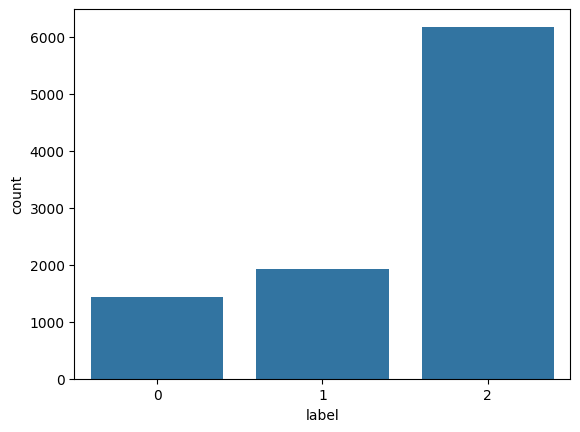

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='label', data=train)

plt.show()

Tweet Length Distribution

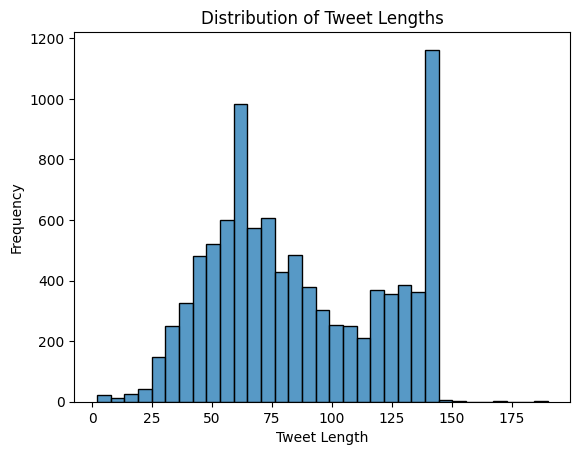

In [5]:
train['length'] = train['text'].apply(len)

sns.histplot(train['length'])
plt.xlabel('Tweet Length')
plt.ylabel('Frequency')
plt.title('Distribution of Tweet Lengths')
plt.show()

Phase 3: Text Cleaning

In [6]:
import re
import unicodedata
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

def clean_text(text):
    text = text.lower()
    text = text.strip()
    text = unicodedata.normalize('NFKC', text)
    text = re.sub(r'http://\S+|https://\S+|www\.\S+', '', text) #remove URLs
    text = re.sub(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9._%+-]+.[A-Za-z0-9._%+-]+', '', text) #remove emails
    text = re.sub(r'@\w+', '', text) #remove mentions
    text = re.sub(r'#\w+', '', text) #remove hashtags
    text = re.sub(r'[^a-zA-Z\s]+', '', text) #remove special characters
    text = re.sub(r'\s+', ' ', text) #remove extra spaces
    cleaned_tokens = word_tokenize(text)
    lemmatizer = WordNetLemmatizer()
    cleaned_tokens_lem = [lemmatizer.lemmatize(token) for token in cleaned_tokens]
    return ' '.join(cleaned_tokens_lem)

In [7]:
train['text'] = train['text'].apply(clean_text)
valid['text'] = valid['text'].apply(clean_text)

In [8]:
train.head(5)

,text,label,length
0,bynd jpmorgan reel in expectation on beyond meat,0,77
1,ccl rcl nomura point to booking weakness at ca...,0,102
2,cx cemex cut at credit suisse jp morgan on wea...,0,94
3,es btig research cut to neutral,0,59
4,fnko funko slide after piper jaffray pt cut,0,71


In [9]:
import pandas as pd
pd.set_option('display.max_colwidth', None)

Phase 4: Vocabulary Building

In [10]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

word_to_index = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for sentence in train["text"]:

    for word in sentence.split():

        if word not in word_to_index:

            word_to_index[word] = len(word_to_index)

print("Vocabulary Size:", len(word_to_index))

Vocabulary Size: 14132


Phase 5: Text to Sequence

In [11]:
def text_to_sequence(text):

    return [

        word_to_index.get(
            word,
            word_to_index[UNK_TOKEN]
        )

        for word in text.split()
    ]


train_sequences = train["text"].apply(
    text_to_sequence
).tolist()

valid_sequences = valid["text"].apply(
    text_to_sequence
).tolist()

Phase 6: Padding

In [12]:
max_length = max(len(sequence) for sequence in train_sequences + valid_sequences)

def pad_sequence(sequence,max_length):

    sequence = sequence[:max_length]

    sequence = sequence + [

        word_to_index[PAD_TOKEN]

    ] * (max_length - len(sequence))

    return sequence


X_train = [ pad_sequence(sequence, max_length ) for sequence in train_sequences ]
X_valid = [ pad_sequence(sequence, max_length ) for sequence in valid_sequences ]

In [13]:
train["label"].value_counts()

label
2    6178
1    1923
0    1442
Name: count, dtype: int64

In [14]:
y_train = train["label"].values

y_valid = valid["label"].values

Phase 8: Convert to Tensor

In [15]:
import torch
import numpy as np
X_train = torch.tensor(np.array(X_train), dtype=torch.long)
X_valid = torch.tensor(np.array(X_valid), dtype=torch.long)
y_train = torch.tensor(y_train, dtype=torch.long)
y_valid = torch.tensor(y_valid, dtype=torch.long)

In [16]:
print(X_train.shape)
print(y_train.shape)

torch.Size([9543, 29])
torch.Size([9543])


In [17]:
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader

train_dataset = TensorDataset(X_train, y_train)
valid_dataset = TensorDataset(X_valid, y_valid)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32)

Phase 9: Shared RNN/LSTM/GRU Class and training

In [18]:
import torch.nn as nn

class SentimentModel(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, model_type="RNN"):
        super().__init__()
        self.model_type = model_type
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        if model_type == "RNN":
            self.recurrent = nn.RNN(embedding_dim, hidden_dim, batch_first=True)
        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        elif model_type == "GRU":
            self.recurrent = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.embedding(x)
        if self.model_type == "LSTM":
            output, (hidden, cell) = self.recurrent(x)
        else:
            output, hidden = self.recurrent(x)
        hidden = hidden[-1]
        return self.fc(hidden)

vocab_size = len(word_to_index)
embedding_dim = 128
hidden_dim = 128
output_dim = len(train["label"].unique())

models = {"RNN": SentimentModel(vocab_size, embedding_dim, hidden_dim, output_dim, model_type="RNN"),
        "LSTM": SentimentModel(vocab_size, embedding_dim, hidden_dim, output_dim, model_type="LSTM"),
        "GRU": SentimentModel(vocab_size, embedding_dim, hidden_dim, output_dim, model_type="GRU")}


Phase 10: Evaluation Function

In [19]:
import torch.optim as optim
def train_model(model):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(),lr=0.001)
    num_epochs = 15
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1}/{num_epochs} "
              f"Loss: {total_loss:.4f}")
    return model

In [20]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
def evaluate_model(model):
    model.eval()
    predictions = []
    actuals = []
    with torch.no_grad():
        for X_batch, y_batch in valid_loader:
            outputs = model(X_batch)
            preds = torch.argmax(outputs, dim=1)
            predictions.extend(preds.numpy())
            actuals.extend(y_batch.numpy())
    accuracy = accuracy_score(actuals, predictions)
    precision = precision_score(actuals, predictions, average="macro")
    recall = recall_score(actuals, predictions, average="macro")
    f1 = f1_score(actuals, predictions, average="macro")
    return accuracy, precision, recall, f1

In [21]:
results = []
for model_name, model in models.items():
    print(f"\nTraining {model_name}")
    train_model(model)
    accuracy, precision, recall, f1 = evaluate_model(model)
    results.append([model_name, accuracy, precision, recall, f1])

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
results_df


Training RNN
Epoch 1/15 Loss: 268.5334
Epoch 2/15 Loss: 266.6127
Epoch 3/15 Loss: 266.5965
Epoch 4/15 Loss: 266.4660
Epoch 5/15 Loss: 265.4037
Epoch 6/15 Loss: 265.5648
Epoch 7/15 Loss: 258.9695
Epoch 8/15 Loss: 242.4855
Epoch 9/15 Loss: 227.0048
Epoch 10/15 Loss: 207.3944
Epoch 11/15 Loss: 192.4764
Epoch 12/15 Loss: 175.1994
Epoch 13/15 Loss: 162.9401
Epoch 14/15 Loss: 156.1619
Epoch 15/15 Loss: 140.7129

Training LSTM
Epoch 1/15 Loss: 258.3077
Epoch 2/15 Loss: 206.1227
Epoch 3/15 Loss: 171.7917
Epoch 4/15 Loss: 140.2119
Epoch 5/15 Loss: 116.1363
Epoch 6/15 Loss: 92.9335
Epoch 7/15 Loss: 77.3120
Epoch 8/15 Loss: 62.2514
Epoch 9/15 Loss: 52.2278
Epoch 10/15 Loss: 44.7598
Epoch 11/15 Loss: 39.6326
Epoch 12/15 Loss: 36.1503
Epoch 13/15 Loss: 32.4289
Epoch 14/15 Loss: 29.7793
Epoch 15/15 Loss: 32.4246

Training GRU
Epoch 1/15 Loss: 250.4335
Epoch 2/15 Loss: 191.7719
Epoch 3/15 Loss: 143.9631
Epoch 4/15 Loss: 103.6860
Epoch 5/15 Loss: 69.8136
Epoch 6/15 Loss: 45.7100
Epoch 7/15 Loss: 30.6

,Model,Accuracy,Precision,Recall,F1 Score
0,RNN,0.627303,0.475944,0.481118,0.473097
1,LSTM,0.748744,0.664886,0.682963,0.668149
2,GRU,0.735762,0.661755,0.690544,0.662885


Phase 11: Classification Report

In [22]:
from sklearn.metrics import classification_report
best_model = models["LSTM"]

actuals = []
predictions = []
best_model.eval()
with torch.no_grad():
    for X_batch, y_batch in valid_loader:
        outputs = best_model(X_batch)
        preds = torch.argmax(outputs, dim=1)
        actuals.extend(y_batch.numpy())
        predictions.extend(preds.numpy())

print(classification_report(actuals, predictions))

              precision    recall  f1-score   support

           0       0.46      0.63      0.53       347
           1       0.67      0.59      0.63       475
           2       0.86      0.82      0.84      1566

    accuracy                           0.75      2388
   macro avg       0.66      0.68      0.67      2388
weighted avg       0.77      0.75      0.75      2388



In [24]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    actuals,
    predictions
)

cm

array([[ 220,   46,   81],
       [  72,  282,  121],
       [ 189,   91, 1286]])

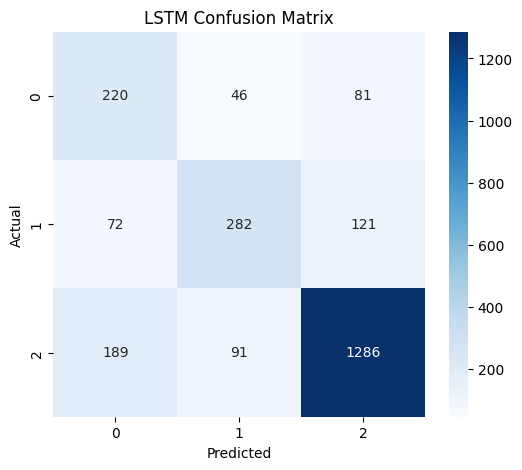

In [25]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title(
    "LSTM Confusion Matrix"
)

plt.show()

Phase 12: Save Best Model

In [26]:
torch.save(
    best_model.state_dict(),
    "best_lstm_model.pt"
)

In [27]:
import os

os.path.exists(
    "best_lstm_model.pt"
)

True

In [28]:
import pickle

with open(
    "vocab.pkl",
    "wb"
) as file:

    pickle.dump(
        word_to_index,
        file
    )